In [2]:
# Cell 1: Install extra libraries
!pip install xgboost lightgbm imbalanced-learn shap --quiet

In [3]:
# Cell 2: All imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    f1_score
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import xgboost as xgb
import lightgbm as lgb
import shap

# Check GPU
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
print(result.stdout[:500] if result.returncode == 0 else "No GPU found")
print(f"\nXGBoost version: {xgb.__version__}")
print(f"LightGBM version: {lgb.__version__}")



Sun Nov  1 08:05:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|       

XGBoost version: 3.4.1
LightGBM version: 4.6.0


In [4]:
# Cell 3: Load data
# Dataset: https://kaggle.com
df = pd.read_csv('/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv')

print("Shape:", df.shape)
print("\nFirst 3 rows:")
df.head(3)


Shape: (284807, 31)

First 3 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


=== Basic Info ===
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values: 0

=== Class Distribution ===
Legit:  284,315 (99.83%)
Fraud:  492 (0.1727%)


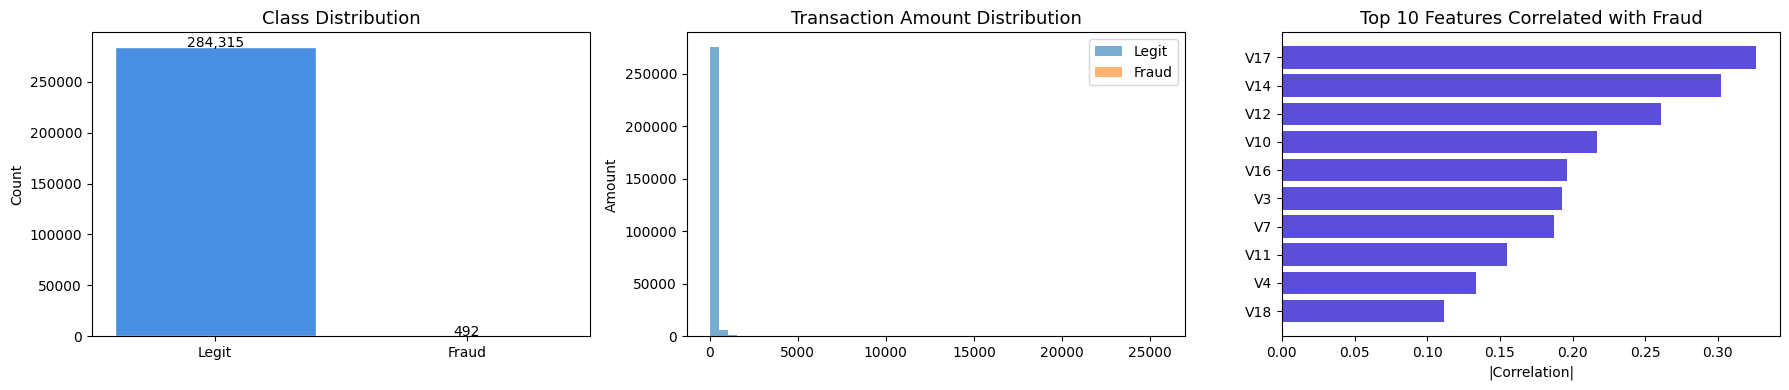


Top correlated features:
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64


In [5]:
# Cell 4: Exploratory Data Analysis
print("=== Basic Info ===")
print(df.dtypes)
print("\nMissing values:", df.isnull().sum().sum())

print("\n=== Class Distribution ===")
class_counts = df['Class'].value_counts()
fraud_pct = class_counts[1] / len(df) * 100
print(f"Legit:  {class_counts[0]:,} ({100-fraud_pct:.2f}%)")
print(f"Fraud:  {class_counts[1]:,} ({fraud_pct:.4f}%)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Class imbalance
axes[0].bar(['Legit', 'Fraud'], class_counts.values,
            color=['#4A90E2', '#E74C3C'], edgecolor='white')
axes[0].set_title('Class Distribution', fontsize=13)
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 100, f'{v:,}', ha='center', fontsize=10)

# Transaction amount by class
df.groupby('Class')['Amount'].plot(kind='hist', bins=50, alpha=0.6,
                                   ax=axes[1], legend=True)
axes[1].set_title('Transaction Amount Distribution', fontsize=13)
axes[1].set_ylabel('Amount')
axes[1].legend(['Legit', 'Fraud'])

# Correlation heatmap (top features)
corr = df.corr()['Class'].drop('Class').abs().sort_values(ascending=False)
top_features = corr.head(10).index
axes[2].barh(top_features[::-1], corr[top_features[::-1]],
          color='#5B4FD9')
axes[2].set_title('Top 10 Features Correlated with Fraud', fontsize=13)
axes[2].set_xlabel('|Correlation|')

plt.tight_layout()
plt.show()

print("\nTop correlated features:")
print(corr.head(10))



In [6]:
# Cell 5: Feature engineering & preprocessing

# Scale 'Amount' and 'Time' (V1-V28 are already PCA-scaled)
df['Amount_log'] = np.log1p(df['Amount'])
df['Hour'] = (df['Time'] % (3600 * 24)) / 3600  # hour of day

# Drop original unscaled columns
df_clean = df.drop(columns=['Time', 'Amount'])

X = df_clean.drop('Class', axis=1)
y = df_clean['Class']

print("Feature matrix shape:", X.shape)
print("Fraud cases:", y.sum())

# Train/test split (stratified to preserve fraud ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\nTrain: {X_train.shape[0]:,} rows | Fraud: {y_train.sum()}")
print(f"Test:  {X_test.shape[0]:,} rows | Fraud: {y_test.sum()}")


Feature matrix shape: (284807, 30)
Fraud cases: 492

Train: 227,845 rows | Fraud: 394
Test:  56,962 rows | Fraud: 98


In [7]:
# Cell 6: Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling done.")
print("Train mean (first feature):", X_train_scaled[:, 0].mean().round(4))
print("Train std  (first feature):", X_train_scaled[:, 0].std().round(4))

Scaling done.
Train mean (first feature): 0.0
Train std  (first feature): 1.0


In [8]:
# Cell 7: SMOTE oversampling on training set ONLY
smote = SMOTE(random_state=42, sampling_strategy=0.1) # fraud -> 10% of majority
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", np.bincount(y_train))
print("After  SMOTE:", np.bincount(y_train_res))


Before SMOTE: [227451    394]
After  SMOTE: [227451  22745]


In [15]:

# Cell 8: Train 4 Models
results = {}

# --- 1. Logistic Regression (Baseline) ---
print("Training Logistic Regression...")

lr = LogisticRegression(
    max_iter=1000,
    C=0.01,
    class_weight='balanced',
    random_state=42
)

lr.fit(X_train_res, y_train_res)
results['LogisticRegression'] = lr

print("Logistic Regression Done.")


# --- 2. Random Forest ---
print("\nTraining Random Forest...")

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train_res, y_train_res)
results['RandomForest'] = rf

print("Random Forest Done.")


# --- 3. XGBoost (GPU) ---
print("\nTraining XGBoost (GPU)...")

xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1,
    tree_method='hist',
    device='cuda',
    eval_metric='aucpr',
    random_state=42,
    verbosity=0,
    early_stopping_rounds=50
)

xgb_model.fit(
    X_train_res,
    y_train_res,
    eval_set=[(X_test_scaled, y_test)],
    verbose=100
)

results['XGBoost'] = xgb_model

print("XGBoost Done.")


# --- 4. LightGBM (GPU) ---
print("\nTraining LightGBM (GPU)...")

lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    device='gpu',
    random_state=42,
    verbosity=-1
)

lgb_model.fit(
    X_train_res,
    y_train_res,
    eval_set=[(X_test_scaled, y_test)],
    eval_metric='auc',
    callbacks=[
        lgb.early_stopping(50, verbose=False),
        lgb.log_evaluation(100)
    ]
)

results['LightGBM'] = lgb_model

print("LightGBM Done.")


print("\nAll 4 models trained successfully.")


Training Logistic Regression...
Logistic Regression Done.

Training Random Forest...
Random Forest Done.

Training XGBoost (GPU)...
[0]	validation_0-aucpr:0.62111
[100]	validation_0-aucpr:0.84716
[200]	validation_0-aucpr:0.85954
[300]	validation_0-aucpr:0.86521
[400]	validation_0-aucpr:0.86930
[499]	validation_0-aucpr:0.87090
XGBoost Done.

Training LightGBM (GPU)...
[100]	valid_0's auc: 0.975488	valid_0's binary_logloss: 0.00908073
LightGBM Done.

All 4 models trained successfully.


In [16]:
# Cell 9: Quick comparison table
summary = []
for name, model in results.items():
    proba = model.predict_proba(X_test_scaled)[:, 1]
    auc   = roc_auc_score(y_test, proba)
    ap    = average_precision_score(y_test, proba)
    preds = (proba >= 0.5).astype(int)
    f1    = f1_score(y_test, preds)
    summary.append({'Model': name, 'ROC-AUC': round(auc, 4),
                    'PR-AUC': round(ap, 4), 'F1 (fraud)': round(f1, 4)})

summary_df = pd.DataFrame(summary).sort_values('PR-AUC', ascending=False)
print(summary_df.to_string(index=False))


             Model  ROC-AUC  PR-AUC  F1 (fraud)
           XGBoost   0.9805  0.8714      0.8384
      RandomForest   0.9806  0.7974      0.6154
          LightGBM   0.9779  0.7934      0.6964
LogisticRegression   0.9713  0.7168      0.1083


Best threshold: 0.875 | Best F1: 0.8729


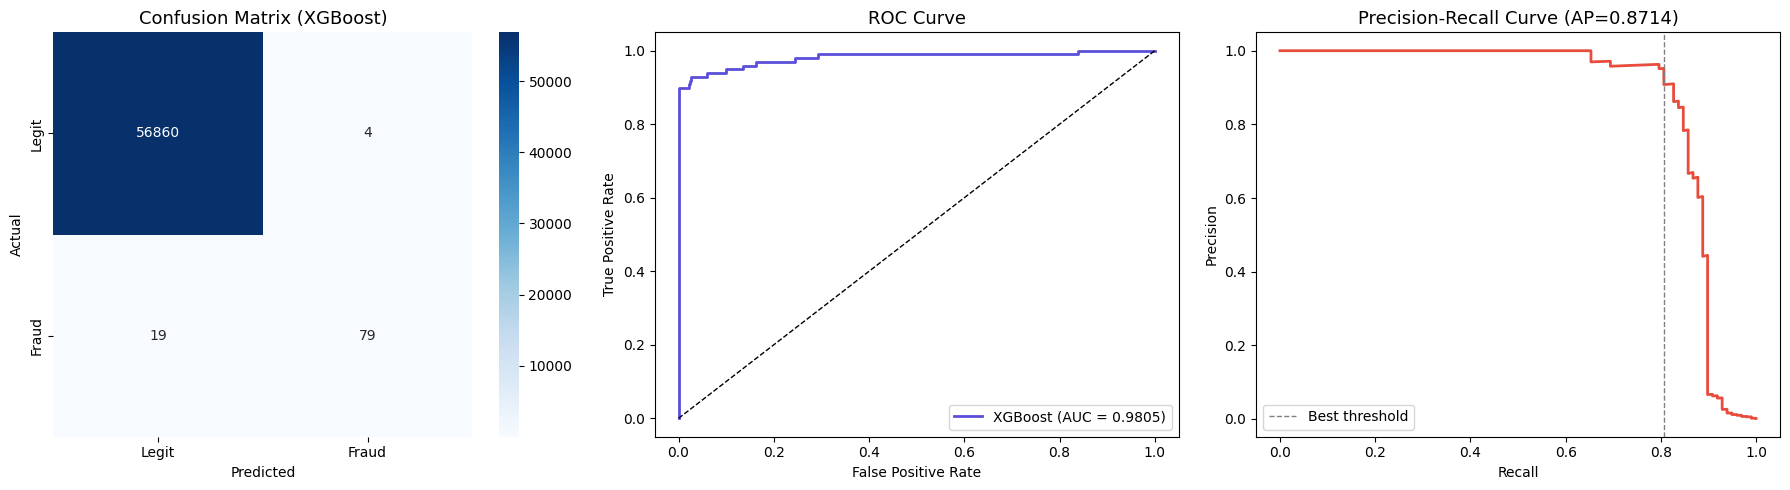


=== Classification Report ===
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00     56864
       Fraud       0.95      0.81      0.87        98

    accuracy                           1.00     56962
   macro avg       0.98      0.90      0.94     56962
weighted avg       1.00      1.00      1.00     56962



In [17]:
# Cell 10: Deep evaluation on best model (XGBoost usually wins)
best_model = results['XGBoost']
proba_best = best_model.predict_proba(X_test_scaled)[:, 1]

# Tune threshold using Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(y_test, proba_best)
f1_scores = 2 * precision * recall / (precision + recall + 1e-9)
best_thresh = thresholds[np.argmax(f1_scores)]
print(f"Best threshold: {best_thresh:.3f} | Best F1: {np.max(f1_scores):.4f}")

y_pred_best = (proba_best >= best_thresh).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legit', 'Fraud'],
            yticklabels=['Legit', 'Fraud'], ax=axes[0])
axes[0].set_title('Confusion Matrix (XGBoost)', fontsize=13)
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, proba_best)
auc_score   = roc_auc_score(y_test, proba_best)
axes[1].plot(fpr, tpr, color='#5B4FD9', lw=2,
             label=f'XGBoost (AUC = {auc_score:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_title('ROC Curve', fontsize=13)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

# Precision-Recall curve
axes[2].plot(recall, precision, color='#E74C3C', lw=2)
axes[2].axvline(recall[np.argmax(f1_scores)], color='gray',
                linestyle='--', lw=1, label='Best threshold')
axes[2].set_title(f'Precision-Recall Curve (AP={average_precision_score(y_test, proba_best):.4f})',
                  fontsize=13)
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].legend()

plt.tight_layout()
plt.show()

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred_best, target_names=['Legit', 'Fraud']))


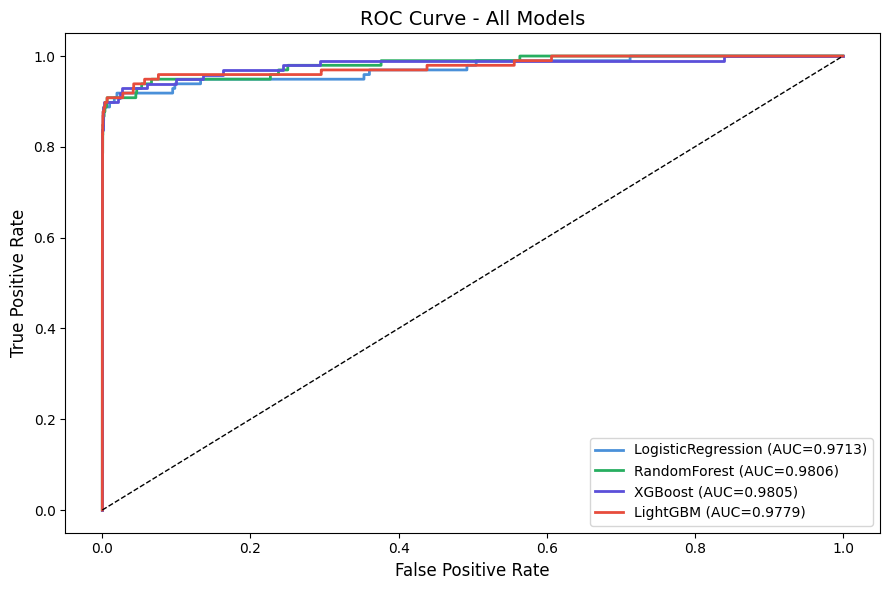

In [18]:
# Cell 11: Side-by-side ROC for all models
plt.figure(figsize=(9, 6))
colors = ['#4A90D9', '#27AE60', '#5B4FD9', '#E74C3C']

for (name, model), color in zip(results.items(), colors):
    proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, lw=2, color=color, label=f'{name} (AUC={auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve - All Models', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


Computing SHAP values (this may take ~30s)...


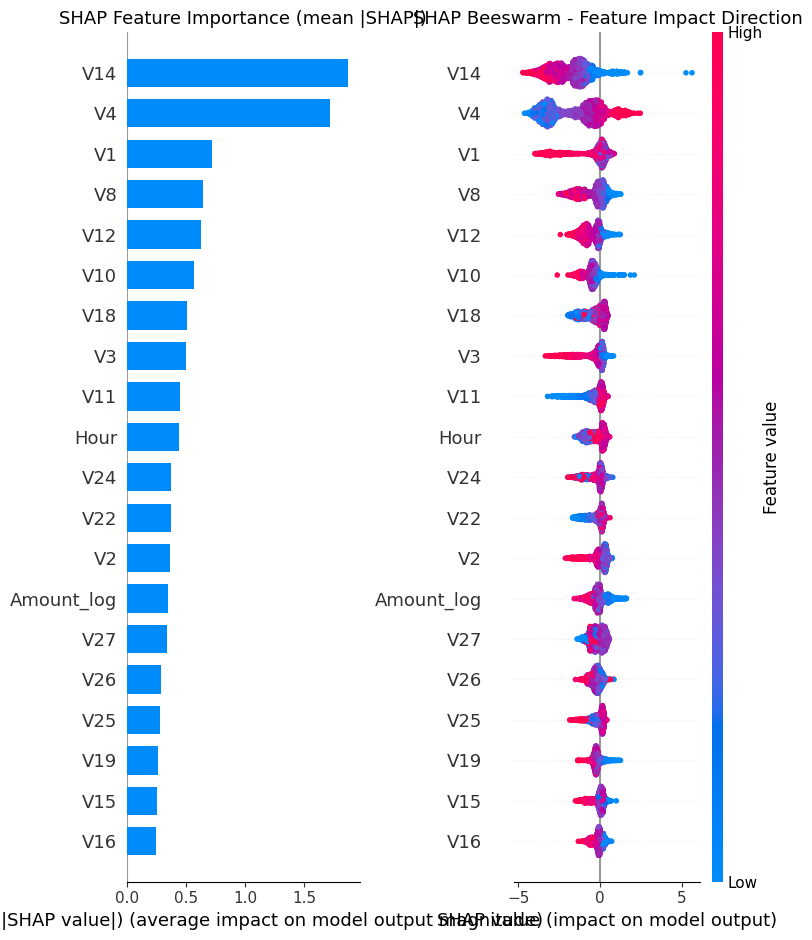


Top 5 fraud-driving features:
V14    1.876279
V4     1.722695
V1     0.720724
V8     0.641689
V12    0.627442
dtype: float32


In [19]:
# Cell 12: SHAP feature importance (XGBoost)
print("Computing SHAP values (this may take ~30s)...")

explainer   = shap.TreeExplainer(results['XGBoost'])
shap_values = explainer.shap_values(X_test_scaled[:2000])  # subset for speed

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

plt.sca(axes[0])
shap.summary_plot(shap_values, X_test_scaled[:2000],
                  feature_names=X.columns.tolist(),
                  plot_type='bar', show=False)
axes[0].set_title('SHAP Feature Importance (mean |SHAP|)', fontsize=13)

plt.sca(axes[1])
shap.summary_plot(shap_values, X_test_scaled[:2000],
                  feature_names=X.columns.tolist(),
                  show=False)
axes[1].set_title('SHAP Beeswarm - Feature Impact Direction', fontsize=13)

plt.tight_layout()
plt.show()

# Top 5 features
mean_shap = np.abs(shap_values).mean(axis=0)
top5 = pd.Series(mean_shap, index=X.columns).sort_values(ascending=False).head(5)
print("\nTop 5 fraud-driving features:")
print(top5)


In [20]:
# Cell 13: Save models to .pkl
import pickle, os

os.makedirs('models', exist_ok=True)

# Save all 4 models
for name, model in results.items():
    path = f'models/{name}.pkl'
    with open(path, 'wb') as f:
        pickle.dump(model, f)
    print(f"Saved: {path}")

print("\nAll models saved ✓")


Saved: models/LogisticRegression.pkl
Saved: models/RandomForest.pkl
Saved: models/XGBoost.pkl
Saved: models/LightGBM.pkl

All models saved ✓
